# Exploración: símbolos, datos y verificadores numericas

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from parabolic_symbol.symbol import Symbol
from parabolic_symbol.symbols.heat import HeatSymbol
from parabolic_symbol.symbols.fractional_laplacian import FractionalLaplacianSymbol
from parabolic_symbol.symbols.counterexample import PurelyImaginarySymbol, SlowDecaySymbol
from parabolic_symbol.data.synthetic import k_grid, make_trajectory_data, split_trajectory_data
from parabolic_symbol.data.grf import grf_variance, grf_wavenumbers, heat_grf_datasets, sample_grf_nd
from parabolic_symbol.learning.estimation import symbol_values
from parabolic_symbol.verification.parabolicity import ParabolicityVerifier
from parabolic_symbol.verification.symbol_class import SymbolClassVerifier
from parabolic_symbol.utils import bracket

np.set_printoptions(precision=4, suppress=True)

# Exponentes de a(k) = |k|^alpha en todo el notebook; alpha = 2 es el calor.
# Cada alpha conserva su color (C0..C3) en todas las figuras.
ALPHAS = [0.5, 1.0, 1.5, 2.0]
COLORS = {alpha: f"C{i}" for i, alpha in enumerate(ALPHAS)}

## 1. Los símbolos

*Dimensión $n=1$: los símbolos son radiales, así que basta verlos en función de $|\mathbf{k}|$.*

$a(\mathbf{k})=|\mathbf{k}|^\alpha$ es el símbolo del Laplaciano fraccionario $(-\Delta)^{\alpha/2}$
(`FractionalLaplacianSymbol`), de orden $m=\alpha$; con $\alpha=2$ es el calor (`HeatSymbol`).

En escala log-log, $|k|^\alpha$ sobre los enteros $k\ge1$ es una recta de pendiente $\alpha$.

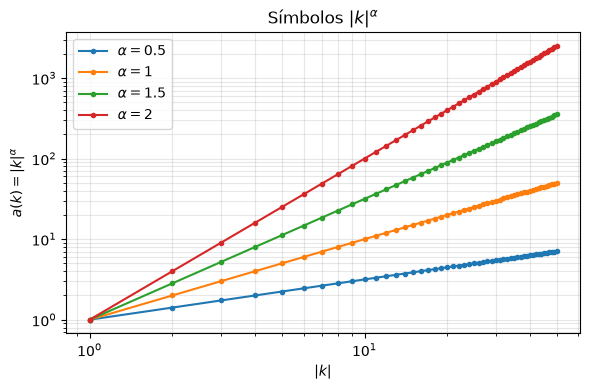

In [48]:
symbols_1d = {alpha: FractionalLaplacianSymbol(n=1, alpha=alpha) for alpha in ALPHAS}

k_line = np.arange(1, 51)[:, None]   # k in Z, k >= 1 (a(-k) = a(k) y a(0) = 0)
a_line = {alpha: symbol_values(s, k_line) for alpha, s in symbols_1d.items()}

fig, ax = plt.subplots(figsize=(6, 4))
for alpha, a in a_line.items():
    ax.loglog(k_line[:, 0], a, "o-", ms=3, color=COLORS[alpha], label=rf"$\alpha={alpha:g}$")
ax.set_xlabel(r"$|k|$")
ax.set_ylabel(r"$a(k)=|k|^\alpha$")
ax.set_title(r"Símbolos $|k|^\alpha$")
ax.legend()
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

El cociente $|k|^\alpha/\langle k\rangle^\alpha$, con $\langle k\rangle=(1+|k|^2)^{1/2}$, sube de $2^{-\alpha/2}$
(en $|k|=1$, línea punteada) hacia $1$ (línea negra): para $k\neq0$ queda acotado en la banda
$[2^{-\alpha/2},1)$, que es lo que permite escribir $a=\langle k\rangle^m\,h$ con $h$ en una banda $(c,C)$,
como hace `ParabolicMLPSymbol`.

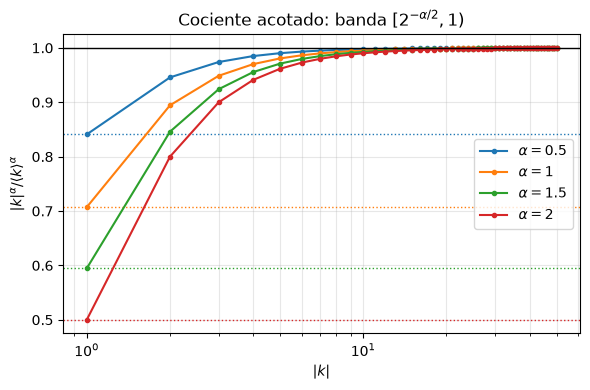

In [49]:
fig, ax = plt.subplots(figsize=(6, 4))
for alpha, a in a_line.items():
    ax.semilogx(k_line[:, 0], a / bracket(k_line) ** alpha, "o-", ms=3, color=COLORS[alpha],
                label=rf"$\alpha={alpha:g}$")
    ax.axhline(2 ** (-alpha / 2), color=COLORS[alpha], ls=":", lw=1)
ax.axhline(1.0, color="k", lw=1)
ax.set_xlabel(r"$|k|$")
ax.set_ylabel(r"$|k|^\alpha / \langle k\rangle^\alpha$")
ax.set_title(r"Cociente acotado: banda $[2^{-\alpha/2}, 1)$")
ax.legend()
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

## 2. Datos

*Dimensión $n=1$: son los datos de `03_barrido_grf.ipynb` (calor 1D del paper base, Sec. 5.1), con la misma
configuración y semilla.*

$u_0\sim\mathcal N\big(0,\ 7^4(-\Delta+7^2)^{-2.5}\big)$ en una malla de $1024$ puntos de $[0,2\pi)$, y
$\hat u(t,k)=e^{-tk^2}\hat u_0(k)$. Entrenamiento: $100$ condiciones iniciales y $10$ tiempos; prueba: $20$
condiciones iniciales nuevas y $20$ tiempos. Se guardan solo los pares $(k,t)$ recuperables en `float32`.

In [50]:
reference_grf = HeatSymbol(n=1)
grf_train, grf_test = heat_grf_datasets(reference_grf, resolution=1024, dtype=torch.float32, seed=0)

resolution = grf_train.resolution
x = 2 * np.pi * np.arange(resolution) / resolution


def to_physical(u_hat):
    # u(x_j) = sum_k u_hat(k) e^{i k x_j}, con u_hat en el orden de np.fft (convencion de data/grf.py)
    return resolution * np.real(np.fft.ifft(u_hat, axis=-1))

ENTRENAMIENTO
100 condiciones iniciales x 10 tiempos, resolucion 1024: 142 de 10240 pares (k, t) recuperables (eps=1.19e-07) -> 14,200 muestras
  ventana de k recuperable: 35 k, |k|_inf <= 17, |k| in [0, 17]
  max |k| por tiempo: t=0.05:17, t=0.15:10, t=0.25:7, t=0.35:6, t=0.45:5, t=0.55:5, t=0.65:4, t=0.75:4, t=0.85:4, t=0.95:4
PRUEBA
20 condiciones iniciales x 20 tiempos, resolucion 1024: 268 de 20480 pares (k, t) recuperables (eps=1.19e-07) -> 5,360 muestras
  ventana de k recuperable: 35 k, |k|_inf <= 17, |k| in [0, 17]
  max |k| por tiempo: t=0.05:17, t=0.10:12, t=0.15:10, t=0.20:8, t=0.25:7, t=0.30:7, t=0.35:6, t=0.40:6, t=0.45:5, t=0.50:5, t=0.55:5, t=0.60:5, t=0.65:4, t=0.70:4, t=0.75:4, t=0.80:4, t=0.85:4, t=0.90:4, t=0.95:4, t=1.00:3


Cuatro condiciones iniciales $u_0(x)$ del conjunto de entrenamiento: campos reales y suaves, con
la energía concentrada en $|k|\lesssim7$.

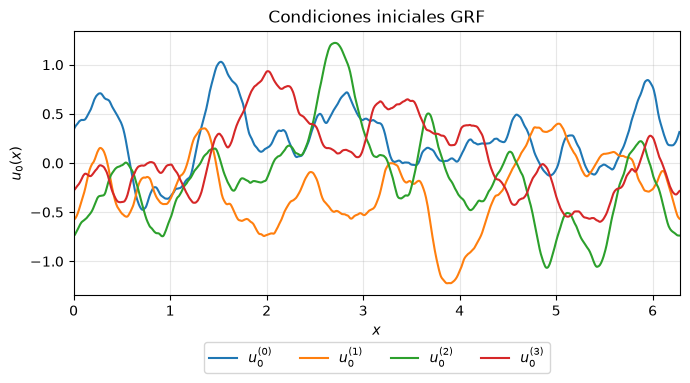

In [51]:
u0 = to_physical(grf_train.u0_hat[:4])

fig, ax = plt.subplots(figsize=(7, 4))
for i, u in enumerate(u0):
    ax.plot(x, u, lw=1.5, color=f"C{i}", label=f"$u_0^{{({i})}}$")
ax.set_xlim(0, 2 * np.pi)
ax.set_xlabel("$x$")
ax.set_ylabel("$u_0(x)$")
ax.set_title("Condiciones iniciales GRF")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.15))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Espectro medio $|\hat u_0(k)|^2$ sobre las $100$ condiciones iniciales de entrenamiento, frente a la curva
teórica $\mathbb E|\hat u_0(k)|^2=7^4(k^2+49)^{-2.5}/2\pi$ (`grf_variance`): coinciden, plana hasta $k\approx7$
y con pendiente $-5$ después.

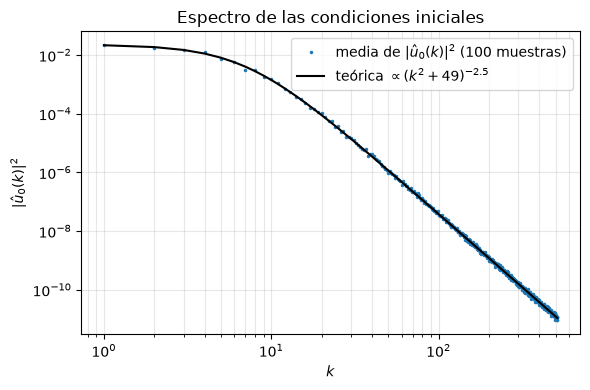

In [52]:
k_pos = np.arange(1, resolution // 2 + 1)   # k >= 1 (las -k tienen la misma varianza)
spectrum = np.mean(np.abs(grf_train.u0_hat[:, k_pos]) ** 2, axis=0)

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(k_pos, spectrum, ".", ms=3, color="C0", label=r"media de $|\hat u_0(k)|^2$ (100 muestras)")
ax.loglog(k_pos, grf_variance(k_pos) / (2 * np.pi), "k-", lw=1.5,
          label=r"teórica $\propto (k^2+49)^{-2.5}$")
ax.set_xlabel("$k$")
ax.set_ylabel(r"$|\hat u_0(k)|^2$")
ax.set_title("Espectro de las condiciones iniciales")
ax.legend()
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

Evolución de la primera condición inicial, $u(t,x)=\sum_k e^{-tk^2}\hat u_0(k)e^{ikx}$: el calor amortigua
primero los modos altos y $u$ tiende a la constante $\hat u_0(0)$.

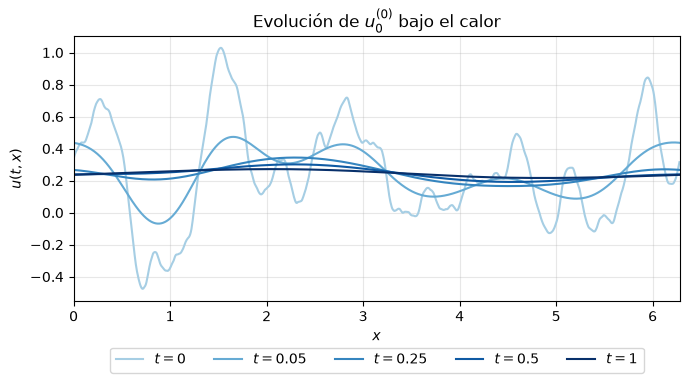

In [53]:
t_evol = [0.0, 0.05, 0.25, 0.5, 1.0]
shades = plt.cm.Blues(np.linspace(0.35, 1.0, len(t_evol)))   # un solo tono: claro = t pequeno

fig, ax = plt.subplots(figsize=(7, 4))
for t, color in zip(t_evol, shades):
    u_t = to_physical(np.exp(-t * grf_train.a) * grf_train.u0_hat[0])
    ax.plot(x, u_t, lw=1.5, color=color, label=f"$t={t:g}$")
ax.set_xlim(0, 2 * np.pi)
ax.set_xlabel("$x$")
ax.set_ylabel("$u(t, x)$")
ax.set_title(r"Evolución de $u_0^{(0)}$ bajo el calor")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.15))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Mapa espacio-tiempo de la misma condición inicial: $u(t,x)$ con $x$ en horizontal y $t\in[0,1]$ en vertical
($201$ tiempos). Las oscilaciones finas se borran en los primeros instantes y para $t$ grande solo sobreviven
los modos más bajos.

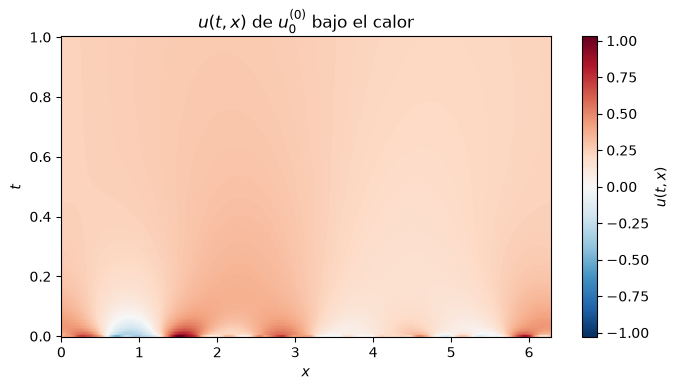

In [54]:
t_fine = np.linspace(0.0, 1.0, 201)


def spacetime(a, u0_hat):
    # u(t, x) sobre (t_fine, x), con u_hat(t, k) = exp(-t a(k)) u0_hat(k); forma (T, resolution)
    return to_physical(np.exp(-t_fine[:, None] * a[None, :]) * u0_hat[None, :])


u_heat = spacetime(grf_train.a, grf_train.u0_hat[0])
u_lim = np.abs(u_heat).max()   # escala de color simetrica, compartida con la figura del fraccionario

fig, ax = plt.subplots(figsize=(7, 4))
mesh = ax.pcolormesh(x, t_fine, u_heat, cmap="RdBu_r", vmin=-u_lim, vmax=u_lim, shading="auto")
fig.colorbar(mesh, ax=ax, label="$u(t, x)$")
ax.set_xlabel("$x$")
ax.set_ylabel("$t$")
ax.set_title(r"$u(t, x)$ de $u_0^{(0)}$ bajo el calor")
plt.tight_layout()
plt.show()

Una condición inicial GRF en $\mathbb T^2=[0,2\pi)^2$, con la misma covarianza $7^4(-\Delta+7^2)^{-2.5}$ y
resolución $128\times128$, evolucionada con el calor $a(\mathbf k)=|\mathbf k|^2$ en
$t\in\{0,0.01,0.05,0.2,1\}$, con la misma escala de color en todos los paneles. Es solo ilustrativa: no
forma parte de ningún entrenamiento.

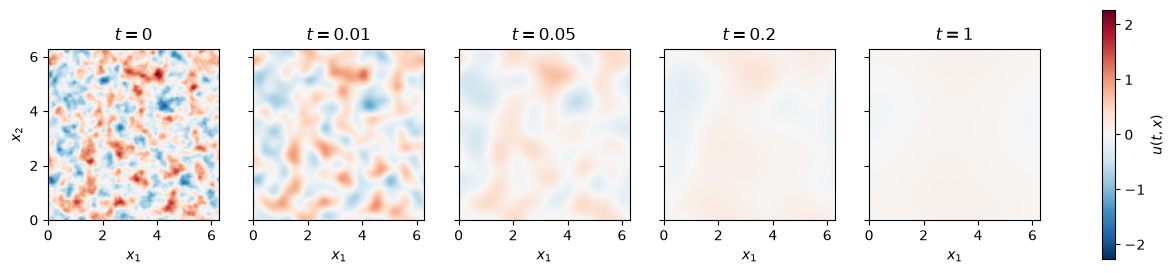

In [55]:
res_2d = 128
k_1d = np.rint(np.fft.fftfreq(res_2d, d=1.0 / res_2d)).astype(int)   # orden de np.fft
K1, K2 = np.meshgrid(k_1d, k_1d, indexing="ij")
k_2d = np.stack([K1.ravel(), K2.ravel()], axis=1)
a_2d = symbol_values(HeatSymbol(n=2), k_2d).reshape(res_2d, res_2d)

# Misma convencion que sample_grf, en T^2: e_k = e^{i k.x} / (2 pi), asi que
# u0_hat(k) = sigma_k xi_k / (2 pi) con sigma_k^2 = grf_variance(|k|). xi = fft2(ruido blanco real) / res_2d
# tiene E|xi_k|^2 = 1 y la simetria xi_{-k} = conj(xi_k), asi que u0 sale real.
rng_2d = np.random.default_rng(0)
xi = np.fft.fft2(rng_2d.standard_normal((res_2d, res_2d))) / res_2d
u0_hat_2d = np.sqrt(grf_variance(np.sqrt(K1**2 + K2**2))) / (2 * np.pi) * xi

t_2d = [0.0, 0.01, 0.05, 0.2, 1.0]
# u(t, x) = sum_k u_hat(t, k) e^{i k.x}, indices [x1, x2]
u_2d = [res_2d**2 * np.real(np.fft.ifft2(np.exp(-t * a_2d) * u0_hat_2d)) for t in t_2d]
lim_2d = np.abs(u_2d[0]).max()

fig, axes = plt.subplots(1, len(t_2d), figsize=(16, 3.6), sharey=True)
for ax, t, u in zip(axes, t_2d, u_2d):
    img = ax.imshow(u.T, origin="lower", extent=[0, 2 * np.pi, 0, 2 * np.pi],
                    cmap="RdBu_r", vmin=-lim_2d, vmax=lim_2d)
    ax.set_title(f"$t={t:g}$")
    ax.set_xlabel("$x_1$")
axes[0].set_ylabel("$x_2$")
fig.colorbar(img, ax=axes, label="$u(t, x)$", shrink=0.9)
plt.show()

Calor frente a fraccionario: la misma $u_0$ del mapa espacio-tiempo evolucionada con $a(k)=|k|^\alpha$ para
$\alpha\in\{0.5,1,2\}$, con la misma escala de color. Con $\alpha$ pequeño los modos altos decaen más despacio
(como $e^{-t|k|^\alpha}$) y la estructura fina dura más; con $\alpha=2$ es el mapa anterior.

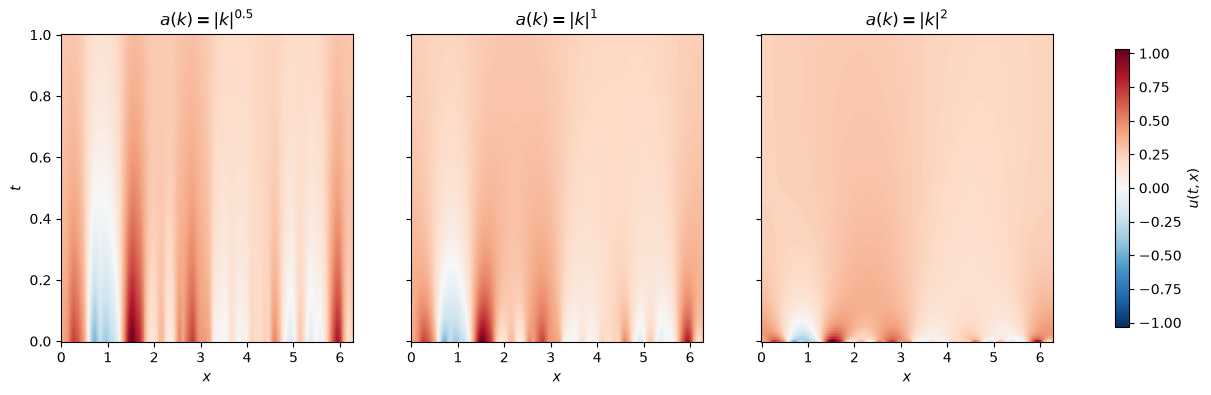

In [56]:
alphas_evol = [0.5, 1.0, 2.0]

fig, axes = plt.subplots(1, len(alphas_evol), figsize=(16, 4), sharey=True)
for ax, alpha in zip(axes, alphas_evol):
    a_alpha = symbol_values(symbols_1d[alpha], grf_train.k[:, None])
    mesh = ax.pcolormesh(x, t_fine, spacetime(a_alpha, grf_train.u0_hat[0]), cmap="RdBu_r",
                         vmin=-u_lim, vmax=u_lim, shading="auto")
    ax.set_title(rf"$a(k)=|k|^{{{alpha:g}}}$")
    ax.set_xlabel("$x$")
axes[0].set_ylabel("$t$")
fig.colorbar(mesh, ax=axes, label="$u(t, x)$", shrink=0.9)
plt.show()

### 2.3 Exploración visual: calor y fraccionario

*Dimensión $n=1$ y $n=2$: las mismas figuras en la recta y en el plano. Es solo ilustrativa: no forma parte de
ningún entrenamiento.*

Solo campos GRF, $u_0\sim\mathcal N\big(0,\ 7^4(-\Delta+7^2)^{-2.5}\big)$ en $\mathbb T^n=[0,2\pi)^n$ con
$u(\mathbf x)=\sum_{\mathbf k}\hat u(\mathbf k)e^{i\mathbf k\cdot\mathbf x}$, evolucionados exactamente con
$\hat u(t,\mathbf k)=e^{-t|\mathbf k|^\alpha}\hat u_0(\mathbf k)$ para $\alpha\in\{0.5,1,2\}$ ($\alpha=2$ es el
calor). El $2.5$ de la covarianza es la regularidad del campo inicial, no el $\alpha$ del operador.

- 1D: las $100$ condiciones iniciales de entrenamiento de 2.2 (malla de $1024$ puntos).
- 2D: $20$ condiciones iniciales nuevas de `sample_grf_nd`, malla de $128\times128$.

In [57]:
ALPHAS_OP = [0.5, 1.0, 2.0]   # alpha del operador, a(k) = |k|^alpha (no el 2.5 de la covarianza)

# 1D: condiciones iniciales de entrenamiento de 2.2, coeficientes en el orden de np.fft
u0_hat_1 = grf_train.u0_hat                                                   # (100, 1024)
a1 = {alpha: symbol_values(symbols_1d[alpha], grf_train.k[:, None]) for alpha in ALPHAS_OP}

# 2D: 20 condiciones iniciales en T^2, coeficientes en el layout de rfftn
res2 = 128
u0_2, u0_hat_2 = sample_grf_nd(20, res2, n=2, rng=np.random.default_rng(1))  # (20, 128, 128), (20, 128, 65)
k2 = grf_wavenumbers(res2, n=2).reshape(-1, 2)
a2 = {
    alpha: symbol_values(FractionalLaplacianSymbol(n=2, alpha=alpha), k2).reshape(u0_hat_2.shape[1:])
    for alpha in ALPHAS_OP
}


def evolve_1d(alpha, t, u0_hat=u0_hat_1):
    # u(t, x) en la malla de 1024 puntos: u_hat(t, k) = exp(-t |k|^alpha) u0_hat(k)
    return to_physical(np.exp(-t * a1[alpha]) * u0_hat)


def evolve_2d(alpha, t, u0_hat=u0_hat_2):
    # u(t, x1, x2) en la malla 128 x 128, indices [..., x1, x2]
    return res2**2 * np.fft.irfftn(np.exp(-t * a2[alpha]) * u0_hat, s=(res2, res2), axes=(-2, -1))


def diverging_limits(u):
    # Escala divergente centrada en la media de u (la media espacial no cambia con t: a(0) = 0)
    center = u.mean()
    half = np.abs(u - center).max()
    return center - half, center + half


extent_2 = [0, 2 * np.pi, 0, 2 * np.pi]
print(f"1D: {u0_hat_1.shape[0]} condiciones iniciales, malla {resolution}")
print(f"2D: {u0_2.shape[0]} condiciones iniciales, malla {res2}x{res2}")

1D: 100 condiciones iniciales, malla 1024
2D: 20 condiciones iniciales, malla 128x128


**a) Evolución del calor ($\alpha=2$).** En 1D este papel lo cumple la figura de evolución de 2.2. En 2D, la
primera condición inicial en $t\in\{0,0.01,0.05,0.2,1\}$, con la misma escala de color centrada en la media:
la estructura fina desaparece primero y el campo se aplana hacia su media.

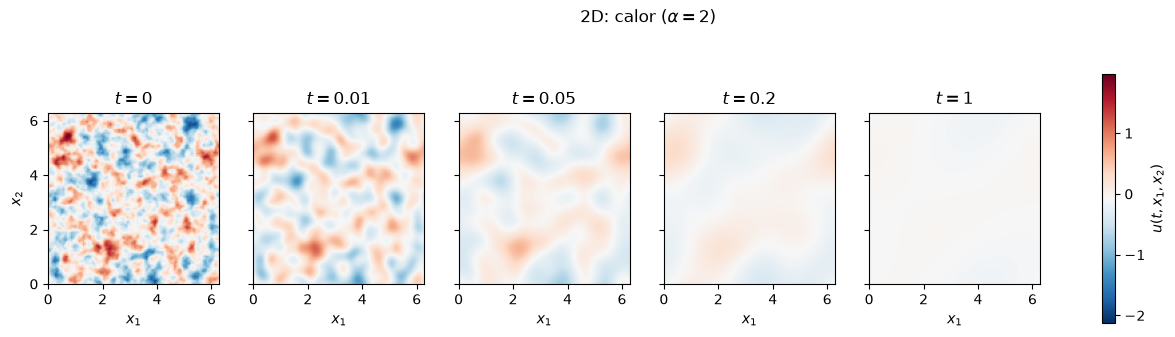

In [58]:
T_HEAT = [0.0, 0.01, 0.05, 0.2, 1.0]
u_heat_2 = [evolve_2d(2.0, t, u0_hat_2[0]) for t in T_HEAT]
vmin, vmax = diverging_limits(u_heat_2[0])

fig, axes = plt.subplots(1, len(T_HEAT), figsize=(16, 3.6), sharey=True)
for ax, t, u in zip(axes, T_HEAT, u_heat_2):
    img = ax.imshow(u.T, origin="lower", extent=extent_2, cmap="RdBu_r", vmin=vmin, vmax=vmax)
    ax.set_title(f"$t={t:g}$")
    ax.set_xlabel("$x_1$")
axes[0].set_ylabel("$x_2$")
fig.colorbar(img, ax=axes, label=r"$u(t, x_1, x_2)$", shrink=0.9)
fig.suptitle(r"2D: calor ($\alpha=2$)", y=1.02)
plt.show()

**b) Calor frente a fraccionario.** En 1D, la primera condición inicial y sus evoluciones a $t=0.05$ con
$\alpha\in\{0.5,1,2\}$, superpuestas: con $\alpha$ menor los modos altos se amortiguan menos ($e^{-t|k|^\alpha}$
decae más despacio en $|k|$) y la curva queda más cerca de $u_0$.

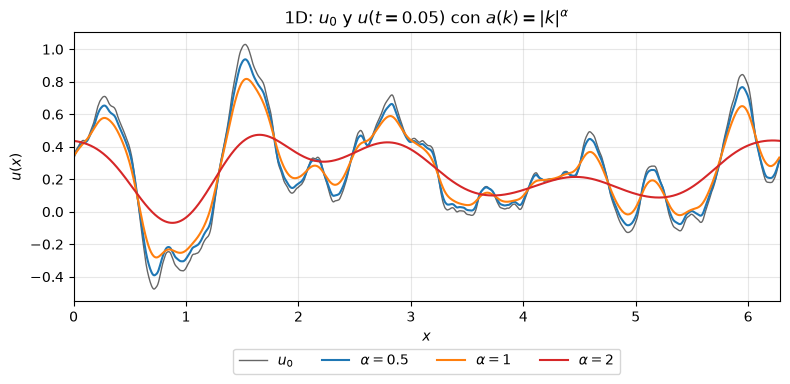

In [59]:
T_CMP = 0.05

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, evolve_1d(2.0, 0.0, u0_hat_1[0]), color="k", lw=1, alpha=0.6, label="$u_0$")
for alpha in ALPHAS_OP:
    ax.plot(x, evolve_1d(alpha, T_CMP, u0_hat_1[0]), lw=1.5, color=COLORS[alpha],
            label=rf"$\alpha={alpha:g}$")
ax.set_xlim(0, 2 * np.pi)
ax.set_xlabel("$x$")
ax.set_ylabel("$u(x)$")
ax.set_title(rf"1D: $u_0$ y $u(t={T_CMP:g})$ con $a(k)=|k|^\alpha$")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.15))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

En 2D, la primera condición inicial y sus evoluciones a $t=0.05$ con $\alpha\in\{0.5,1,2\}$, con la misma escala
de color: con $\alpha=0.5$ el campo apenas cambia y con el calor ya está visiblemente suavizado.

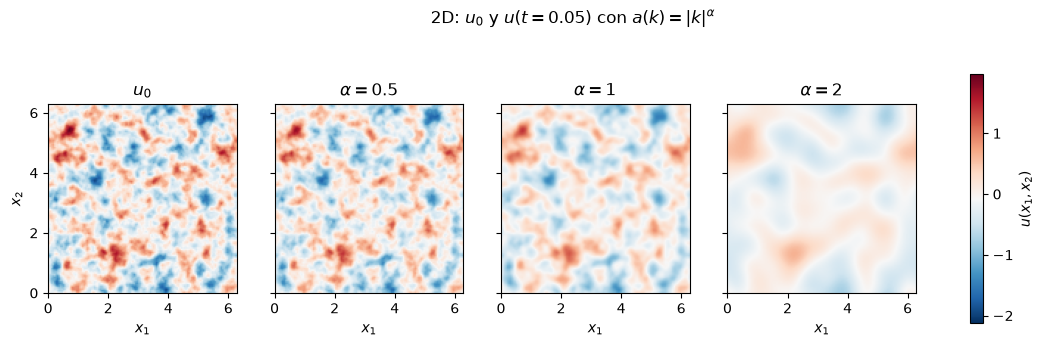

In [60]:
panels = [("$u_0$", evolve_2d(2.0, 0.0, u0_hat_2[0]))]
panels += [(rf"$\alpha={alpha:g}$", evolve_2d(alpha, T_CMP, u0_hat_2[0])) for alpha in ALPHAS_OP]
vmin, vmax = diverging_limits(panels[0][1])

fig, axes = plt.subplots(1, len(panels), figsize=(14, 3.6), sharey=True)
for ax, (title, u) in zip(axes, panels):
    img = ax.imshow(u.T, origin="lower", extent=extent_2, cmap="RdBu_r", vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.set_xlabel("$x_1$")
axes[0].set_ylabel("$x_2$")
fig.colorbar(img, ax=axes, label="$u(x_1, x_2)$", shrink=0.9)
fig.suptitle(rf"2D: $u_0$ y $u(t={T_CMP:g})$ con $a(k)=|k|^\alpha$", y=1.02)
plt.show()

**c) El símbolo $a(\mathbf k)=|\mathbf k|^\alpha$.** En 1D lo muestran las curvas de la sección 1. En 2D, mapas
sobre $(k_1,k_2)\in[-12,12]^2$, cada uno con su barra de color: como el símbolo es radial, los niveles son
anillos concéntricos; con $\alpha=0.5$ el color cambia sobre todo cerca del origen y con $\alpha=2$ lejos de él.

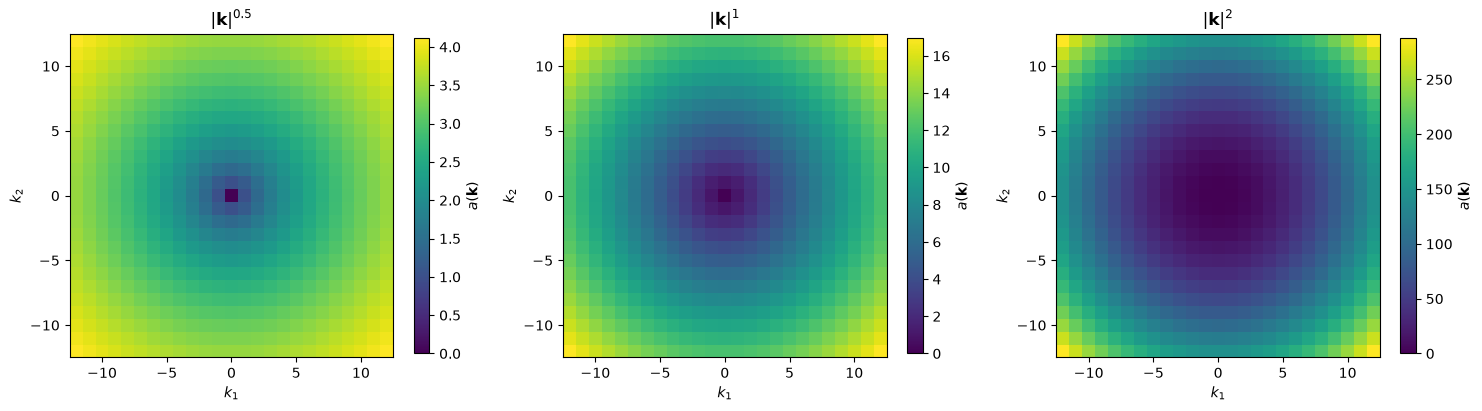

In [73]:
K_SYM = 12
k_sym = k_grid(2, K_SYM)   # orden de np.ndindex: reshape a [k1, k2]
side = 2 * K_SYM + 1

fig, axes = plt.subplots(1, len(ALPHAS_OP), figsize=(15, 4.2))
for ax, alpha in zip(axes, ALPHAS_OP):
    a_sym = symbol_values(FractionalLaplacianSymbol(n=2, alpha=alpha), k_sym).reshape(side, side)
    img = ax.imshow(a_sym.T, origin="lower", cmap="viridis",
                    extent=[-K_SYM - 0.5, K_SYM + 0.5, -K_SYM - 0.5, K_SYM + 0.5])
    fig.colorbar(img, ax=ax, label=r"$a(\mathbf{k})$", shrink=0.85)
    ax.set_title(rf"$|\mathbf{{k}}|^{{{alpha:g}}}$")
    ax.set_xlabel("$k_1$")
    ax.set_ylabel("$k_2$")
plt.tight_layout()
plt.show()

**d) Distribución de los valores de $u$.** Histogramas (densidad) de todos los valores de $u$ sobre las
condiciones iniciales ($100$ en 1D, arriba; $20$ en 2D, abajo) en $t\in\{0,0.05,0.25,1\}$, un panel por $\alpha$,
con los mismos ejes en todos: la distribución se estrecha con $t$, y más rápido cuanto mayor es $\alpha$.

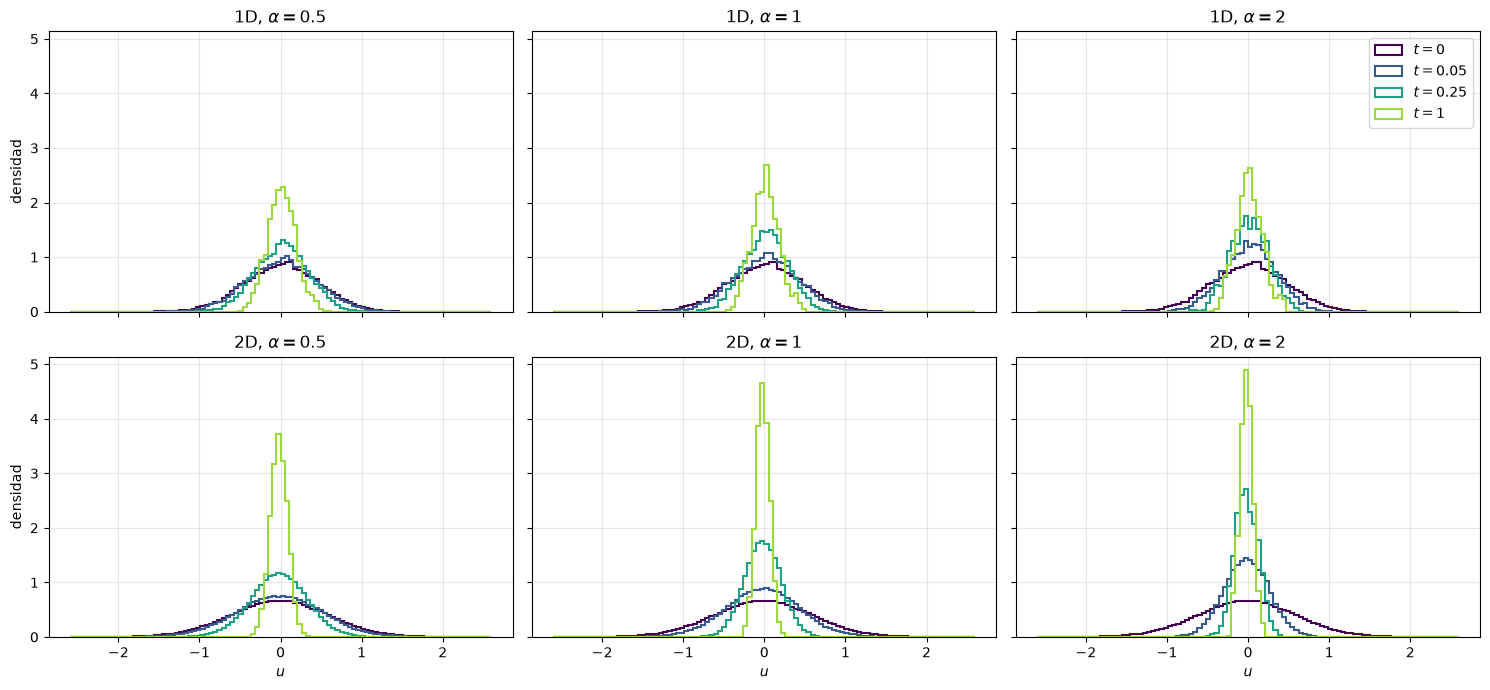

In [74]:
T_HIST = [0.0, 0.05, 0.25, 1.0]
shades = plt.cm.viridis(np.linspace(0, 0.85, len(T_HIST)))   # oscuro = t pequeno; sin el amarillo final
evolvers = {"1D": evolve_1d, "2D": evolve_2d}

# Bins comunes a todos los paneles: en t = 0 el rango de u es el mas ancho
u_max = max(np.abs(evolve(2.0, 0.0)).max() for evolve in evolvers.values())
bins = np.linspace(-u_max, u_max, 101)

fig, axes = plt.subplots(len(evolvers), len(ALPHAS_OP), figsize=(15, 7), sharex=True, sharey=True)
for row, (dim, evolve) in zip(axes, evolvers.items()):
    for ax, alpha in zip(row, ALPHAS_OP):
        for t, color in zip(T_HIST, shades):
            ax.hist(evolve(alpha, t).ravel(), bins=bins, density=True, histtype="step", lw=1.5,
                    color=color, label=f"$t={t:g}$")
        ax.set_title(rf"{dim}, $\alpha={alpha:g}$")
        ax.grid(alpha=0.3)
for ax in axes[-1]:
    ax.set_xlabel("$u$")
for ax in axes[:, 0]:
    ax.set_ylabel("densidad")
axes[0, -1].legend()
plt.tight_layout()
plt.show()

## 3. Parabolicidad: casos positivos

*Dimensión $n=1$: los símbolos son radiales y el peor caso está en $|\mathbf{k}|=1$, así que $\hat\kappa$ no
cambia con $n$.*

La Def. 2.3 pide $\|(a(\mathbf{k})+\lambda)^{-1}\|\le\kappa\,(1+|(\mathbf{k},\lambda)|^2)^{-m/2}$ para
$\mathrm{Re}\,\lambda\ge0$ y $|(\mathbf{k},\lambda)|\ge\omega$, con
$|(\mathbf{k},\lambda)|=(|\mathbf{k}|^2+|\lambda|^{2/m})^{1/2}$. `ParabolicityVerifier.estimate_kappa`
devuelve $\hat\kappa$, el máximo del cociente
$\|(a(\mathbf{k})+\lambda)^{-1}\|\,(1+|(\mathbf{k},\lambda)|^2)^{m/2}$ sobre una rejilla:

- $\lambda=re^{i\theta}$, con $r$ log-espaciado en $[10^{-3},10^4]$ y $\theta\in[-\pi/2,\pi/2]$ con los
  extremos incluidos (la frontera $\mathrm{Re}\,\lambda=0$);
- $k\in\{-50,\dots,50\}$, incluido $k=0$, y $\omega=1$.

Se usan rejillas de $\lambda$ cada vez más finas, cada una contenida en la siguiente; la tabla usa la más fina.

In [63]:
omega = 1.0
k_par = k_grid(1, 50)   # |k| <= 50, incluido k = 0
REFINEMENTS = [(8, 5), (15, 9), (29, 17), (57, 33), (113, 65)]   # (radios, angulos), anidadas


def lam_grid(n_radii, n_angles):
    # lambda = r e^{i theta}, r log-espaciado en [1e-3, 1e4], theta en [-pi/2, pi/2] con extremos
    radii = np.logspace(-3, 4, n_radii)
    angles = np.linspace(-np.pi / 2, np.pi / 2, n_angles)
    return (radii[:, None] * np.exp(1j * angles)).ravel()


# ~2 min: estimate_kappa recorre la rejilla punto a punto.
kappa_conv = {
    alpha: [ParabolicityVerifier(s).estimate_kappa(k_par, lam_grid(nr, na), omega)
            for nr, na in REFINEMENTS]
    for alpha, s in symbols_1d.items()
}

$\hat\kappa$ en la rejilla más fina ($113\times65$ valores de $\lambda$), frente al valor exacto y a la cota del
Capítulo 3, $\max(2^{(\alpha+1)/2},2)$ (el $2$ cubre $k=0$).

In [64]:
kappa_exact = {0.5: 2**0.25, 1.0: np.sqrt(2), 1.5: np.sqrt(3), 2.0: np.sqrt(5)}

tabla_par = pd.DataFrame([
    {
        "alpha": alpha,
        "kappa_hat": conv[-1],
        "exacto": kappa_exact[alpha],
        "cota Cap. 3": max(2 ** ((alpha + 1) / 2), 2.0),
    }
    for alpha, conv in kappa_conv.items()
])
tabla_par["kappa_hat <= cota"] = tabla_par["kappa_hat"] <= tabla_par["cota Cap. 3"]
nr, na = REFINEMENTS[-1]
print(f"rejilla: {len(k_par)} k x {nr * na} lambda ({nr} radios x {na} angulos), omega = {omega}")
tabla_par.round(4)

rejilla: 101 k x 7345 lambda (113 radios x 65 angulos), omega = 1.0


,alpha,kappa_hat,exacto,cota Cap. 3,kappa_hat <= cota
0,0.5,1.1892,1.1892,2.0000,True
1,1.0,1.4142,1.4142,2.0000,True
2,1.5,1.7320,1.7321,2.3784,True
3,2.0,2.2359,2.2361,2.8284,True


$\hat\kappa$ frente al número de valores de $\lambda$ de la rejilla: como cada rejilla contiene a la anterior,
$\hat\kappa$ solo puede crecer, y se estabiliza en el valor exacto (líneas punteadas).

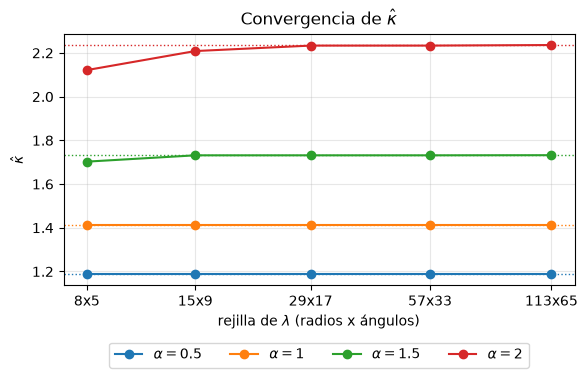

In [65]:
n_lam = [nr * na for nr, na in REFINEMENTS]

fig, ax = plt.subplots(figsize=(6, 4))
for alpha, conv in kappa_conv.items():
    ax.semilogx(n_lam, conv, "o-", color=COLORS[alpha], label=rf"$\alpha={alpha:g}$")
    ax.axhline(kappa_exact[alpha], color=COLORS[alpha], ls=":", lw=1)
ax.set_xticks(n_lam, [f"{nr}x{na}" for nr, na in REFINEMENTS])
ax.minorticks_off()
ax.set_xlabel(r"rejilla de $\lambda$ (radios x ángulos)")
ax.set_ylabel(r"$\hat\kappa$")
ax.set_title(r"Convergencia de $\hat\kappa$")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.2))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Para $k=1$ y $\mathrm{Re}\,\lambda=0$, el cociente en función de $\mathrm{Im}\,\lambda$ (simétrico); los máximos
marcados coinciden con $\hat\kappa$ de la tabla. Para $\alpha\le1$ el máximo está en $\lambda=0$; para el calor,
en $\mathrm{Im}\,\lambda=\pm1/2$, con valor $(2+1/2)/|1+i/2|=\sqrt5$.

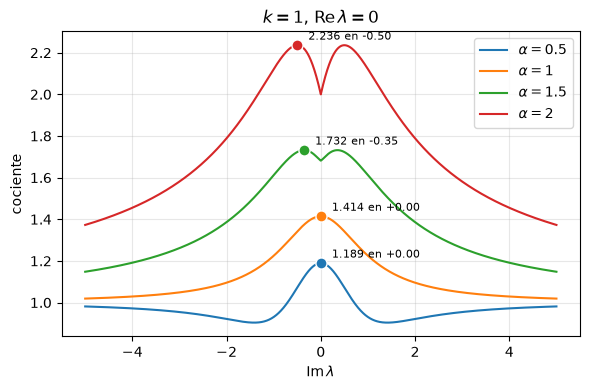

In [66]:
im_lam = np.linspace(-5, 5, 2001)   # paso 0.005: incluye Im(lambda) = -0.5

fig, ax = plt.subplots(figsize=(6, 4))
for alpha, s in symbols_1d.items():
    verifier = ParabolicityVerifier(s)
    # Con kappa = 1, ratio es exactamente el cociente ||(a + lambda)^{-1}|| (1 + |(k, lambda)|^2)^{m/2}
    quotient = np.array([verifier.evaluate_point(np.array([1.0]), 1j * y, kappa=1.0).ratio
                         for y in im_lam])
    i_max = int(np.argmax(quotient))
    ax.plot(im_lam, quotient, color=COLORS[alpha], label=rf"$\alpha={alpha:g}$")
    ax.plot(im_lam[i_max], quotient[i_max], "o", ms=8, color=COLORS[alpha], mec="white")
    ax.annotate(f"{quotient[i_max]:.3f} en {im_lam[i_max]:+.2f}", (im_lam[i_max], quotient[i_max]),
                textcoords="offset points", xytext=(8, 4), fontsize=8)
ax.set_xlabel(r"$\mathrm{Im}\,\lambda$")
ax.set_ylabel("cociente")
ax.set_title(r"$k=1$, $\mathrm{Re}\,\lambda=0$")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Parabolicidad: casos negativos

*Dimensión $n=1$: los dos contraejemplos fallan ya sobre la recta, no hace falta más dimensión.*

**`PurelyImaginarySymbol`**, $a(k)=i|k|$: falla algo más fuerte que la cota; en $\lambda=-i|k|$
(con $\mathrm{Re}\,\lambda=0$) $a(k)+\lambda\,\mathrm{Id}$ deja de ser invertible.

In [67]:
imag_symbol = PurelyImaginarySymbol(n=1)
verifier_imag = ParabolicityVerifier(imag_symbol)

k_critical = np.array([3.0])
lam_critical = -1j * 3.0

try:
    verifier_imag.resolvent(k_critical, lam_critical)
    print("No fallo (revisa el simbolo / la implementacion).")
except np.linalg.LinAlgError as e:
    print(f"Fallo de invertibilidad, como se esperaba:\n  {e}")

Fallo de invertibilidad, como se esperaba:
  a(k) + lambda*Id no es invertible en k=[3.], lambda=(-0-3j)


**`SlowDecaySymbol`**, $a(k)=|k|$ declarando $m=4$: $\hat\kappa$ en $\lambda=0$ frente al tamaño de la ventana
de $k$, que crece sin estabilizarse.

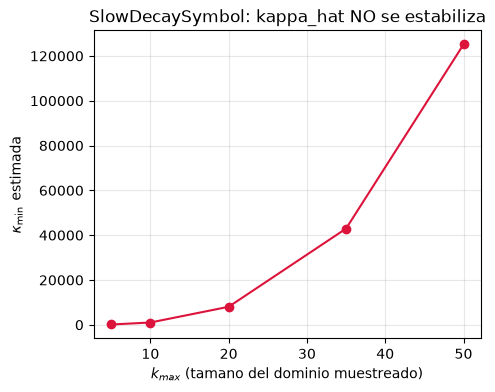

In [68]:
slow = SlowDecaySymbol(n=1)
verifier_slow = ParabolicityVerifier(slow)
lam_zero = [complex(0, 0)]

k_max_values = [5, 10, 20, 35, 50]
kappa_vs_kmax = []
for k_max in k_max_values:
    kh = verifier_slow.estimate_kappa(k_grid(n=1, k_max=k_max), lam_zero, omega=1.0)
    kappa_vs_kmax.append(kh)

plt.figure(figsize=(5, 4))
plt.plot(k_max_values, kappa_vs_kmax, marker="o", color="crimson")
plt.xlabel(r"$k_{max}$ (tamano del dominio muestreado)")
plt.ylabel(r"$\kappa_{\min}$ estimada")
plt.title("SlowDecaySymbol: kappa_hat NO se estabiliza")
plt.grid(True, alpha=0.3)
plt.show()

## 5. Clase $S^{m,\rho}$

*Dimensión $n=2$, para que aparezcan las diferencias mixtas ($\Delta^{(1,1)}$, $\Delta^{(2,1)}$, ...).*

Aparte de la parabolicidad (Def. 2.3), un simbolo debe pertenecer a la clase discreta
$S^{m,\rho}$ (Def. 2.1): para todo multiíndice $|\alpha|\le\rho$ existe $C_\alpha$ con

$$\|\Delta^\alpha_k a(\mathbf{k})\| \le C_\alpha\,\langle \mathbf{k}\rangle^{\,m-|\alpha|}.$$

En esta sección $\alpha$ es el multiíndice (columna `alpha` de las tablas por multiíndice); el exponente del
Laplaciano fraccionario es la columna `alpha` del resumen. El criterio es de una sola cola (la definicion pide
una **cota superior**), y lo que se mide es si $\hat C_\alpha(K)$ deja de crecer al ampliar la ventana
$|k_i|\le K$ y si la pendiente log-log no supera $m-|\alpha|$.

In [69]:
def tabla_clase(symbol, k_maxs=(4, 8, 12, 16)):
    # Una fila por multiindice alpha con la evidencia de la Def. 2.1.
    return pd.DataFrame([
        {
            "alpha": str(r.alpha),
            "|alpha|": r.order,
            **{f"C_hat({K})": r.c_hat[K] for K in k_maxs},
            f"crecim.({k_maxs[-2]}->{k_maxs[-1]})": r.growth,
            "pendiente": r.slope,
            "m-|alpha|": r.slope_theoretical,
            "estable": r.stable,
            "consistente": r.consistent,
        }
        for r in SymbolClassVerifier(symbol).check(k_maxs=k_maxs)
    ])


# Calor en T^2: a(k) = |k|^2 con m = 2. Delta^alpha de un polinomio de grado 2 se
# anula para |alpha| >= 3, asi que ahi C_alpha = 0 y la pendiente queda indefinida.
heat2 = HeatSymbol(n=2)
print(f"{heat2!r}")
display(tabla_clase(heat2))

HeatSymbol(n=2, m=2.0, rho=3, dim=1)


,alpha,|alpha|,C_hat(4),C_hat(8),C_hat(12),C_hat(16),crecim.(12->16),pendiente,m-|alpha|,estable,consistente
0,"(0, 0)",0,0.969697,0.992248,0.996540,0.998051,1.001516,2.008190e+00,2.0,True,True
1,"(0, 1)",1,2.236068,2.236068,2.236068,2.236068,1.000000,9.612849e-01,1.0,True,True
2,"(1, 0)",1,2.236068,2.236068,2.236068,2.236068,1.000000,9.612849e-01,1.0,True,True
3,"(0, 2)",2,2.000000,2.000000,2.000000,2.000000,1.000000,2.181404e-16,0.0,True,True
4,"(1, 1)",2,0.000000,0.000000,0.000000,0.000000,1.000000,NaN,0.0,True,True
5,"(2, 0)",2,2.000000,2.000000,2.000000,2.000000,1.000000,2.181404e-16,0.0,True,True
6,"(0, 3)",3,0.000000,0.000000,0.000000,0.000000,1.000000,NaN,-1.0,True,True
7,"(1, 2)",3,0.000000,0.000000,0.000000,0.000000,1.000000,NaN,-1.0,True,True
8,"(2, 1)",3,0.000000,0.000000,0.000000,0.000000,1.000000,NaN,-1.0,True,True
9,"(3, 0)",3,0.000000,0.000000,0.000000,0.000000,1.000000,NaN,-1.0,True,True


In [70]:
# Laplaciano fraccionario para varios alpha, con m = alpha en cada caso.
resumen_clase = []
for alpha in ALPHAS:
    symbol = FractionalLaplacianSymbol(n=2, alpha=alpha)
    res = SymbolClassVerifier(symbol).check(k_maxs=(4, 8, 12, 16))
    resumen_clase.append({
        "alpha": alpha,
        "m": symbol.m,
        "rho": symbol.rho,
        "consistentes": sum(r.consistent for r in res),
        "multiindices": len(res),
        "peor_crecimiento": max(r.growth for r in res),
        "todos_ok": all(r.consistent for r in res),
    })

pd.DataFrame(resumen_clase)

,alpha,m,rho,consistentes,multiindices,peor_crecimiento,todos_ok
0,0.5,0.5,2,6,6,1.000379,True
1,1.0,1.0,2,6,6,1.000758,True
2,1.5,1.5,3,10,10,1.001137,True
3,2.0,2.0,3,10,10,1.001516,True


In [71]:
# Control negativo: el mismo a(k) = |k|^2, pero declarando m = 1.
# No puede estar en S^{1,rho}: C_alpha_hat(K) crece con la ventana y no se estabiliza.
class OrdenMalDeclarado(Symbol):
    # a(k) = |k|^2 declarando m = 1 (orden subestimado).

    def __init__(self, n: int):
        super().__init__(n=n, m=1.0, rho=n + 1, dim=1, name="OrdenMalDeclarado")

    def evaluate(self, k: np.ndarray) -> np.ndarray:
        k = np.asarray(k, dtype=float)
        return np.array([[np.sum(k**2)]], dtype=complex)


mal = tabla_clase(OrdenMalDeclarado(n=2))
display(mal)
print(f"consistentes: {int(mal['consistente'].sum())} de {len(mal)} "
      "(se esperan fallos en los alpha de orden bajo)")

,alpha,|alpha|,C_hat(4),C_hat(8),C_hat(12),C_hat(16),crecim.(12->16),pendiente,m-|alpha|,estable,consistente
0,"(0, 0)",0,5.570485,11.269772,16.941176,22.605352,1.334344,2.008190e+00,1.0,False,False
1,"(0, 1)",1,9.000000,17.000000,25.000000,33.000000,1.320000,9.612849e-01,0.0,False,False
2,"(1, 0)",1,9.000000,17.000000,25.000000,33.000000,1.320000,9.612849e-01,0.0,False,False
3,"(0, 2)",2,11.489125,22.715633,34.000000,45.299007,1.332324,2.181404e-16,-1.0,False,False
4,"(1, 1)",2,0.000000,0.000000,0.000000,0.000000,1.000000,NaN,-1.0,True,True
5,"(2, 0)",2,11.489125,22.715633,34.000000,45.299007,1.332324,2.181404e-16,-1.0,False,False
6,"(0, 3)",3,0.000000,0.000000,0.000000,0.000000,1.000000,NaN,-2.0,True,True
7,"(1, 2)",3,0.000000,0.000000,0.000000,0.000000,1.000000,NaN,-2.0,True,True
8,"(2, 1)",3,0.000000,0.000000,0.000000,0.000000,1.000000,NaN,-2.0,True,True
9,"(3, 0)",3,0.000000,0.000000,0.000000,0.000000,1.000000,NaN,-2.0,True,True


consistentes: 5 de 10 (se esperan fallos en los alpha de orden bajo)


$\hat C_\alpha(K)$ frente a $K$, una curva por multiíndice y coloreada por $|\alpha|$ (se omiten los
$\hat C_\alpha$ nulos salvo redondeo, $<10^{-8}$, el mismo umbral `atol` de `check`): en los cinco símbolos
positivos las curvas se aplanan; con el orden mal declarado, las de $|\alpha|\le2$ crecen con $K$.

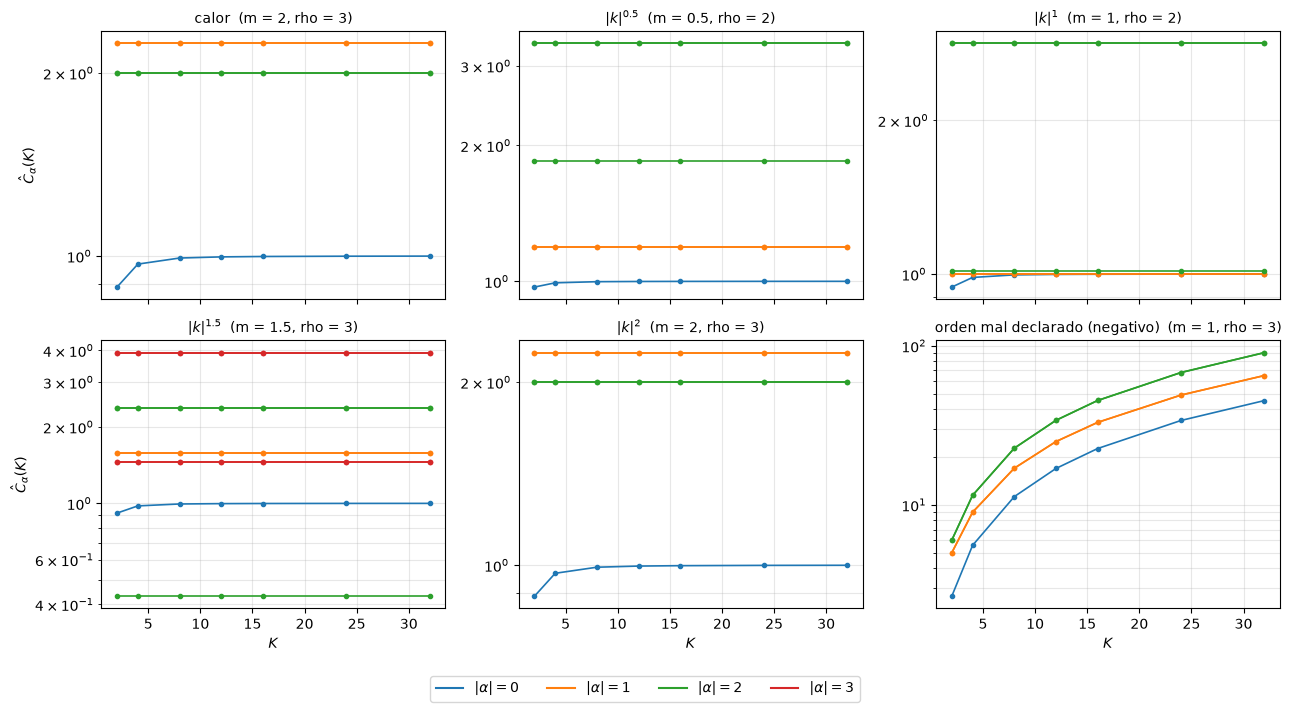

In [72]:
K_FIG = [2, 4, 8, 12, 16, 24, 32]
class_symbols = {"calor": heat2}
class_symbols.update({rf"$|k|^{{{alpha:g}}}$": FractionalLaplacianSymbol(n=2, alpha=alpha) for alpha in ALPHAS})
class_symbols["orden mal declarado (negativo)"] = OrdenMalDeclarado(n=2)

fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
for ax, (name, symbol) in zip(axes.ravel(), class_symbols.items()):
    verifier = SymbolClassVerifier(symbol)
    for alpha in verifier.multi_indices():
        c_hat = np.array(list(verifier.constants(alpha, K_FIG).values()))
        if c_hat.max() > 1e-8:   # nulas salvo redondeo (mismo umbral que atol de check)
            ax.semilogy(K_FIG, c_hat, "o-", ms=3, lw=1.2, color=f"C{sum(alpha)}")
    ax.set_title(f"{name}  (m = {symbol.m:g}, rho = {symbol.rho})", fontsize=10)
    ax.grid(alpha=0.3, which="both")
for ax in axes[-1]:
    ax.set_xlabel("$K$")
for ax in axes[:, 0]:
    ax.set_ylabel(r"$\hat C_\alpha(K)$")
orders = range(max(s.rho for s in class_symbols.values()) + 1)
fig.legend([plt.Line2D([], [], color=f"C{o}") for o in orders], [rf"$|\alpha| = {o}$" for o in orders],
           loc="lower center", ncol=len(orders), bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()